# Reliable Medical Image Classification with Limited Labels
**PatchCamelyon (PCam) · pretrained CNN vs. pretrained ViT · label-budget study · calibration & reliability**

**Research question.** Can pretrained visual representations improve histopathological image classification when only a small fraction of the training labels is available — and can we trust the model's confidence?

**Design**
| Axis | Choice |
|---|---|
| Encoders (frozen) | ResNet-50 (CNN) vs. ViT-B/16 — both ImageNet-1k supervised, so the comparison isolates *architecture*, not pre-training data |
| Heads | Linear probe, 1-hidden-layer MLP |
| Label budgets | 10 %, 25 %, 50 %, 100 % of train labels (nested, class-stratified subsets) |
| Seeds | 3 per configuration → mean ± std |
| Metrics | macro-F1, balanced accuracy, AUROC, ECE, Brier, NLL |
| Reliability | reliability diagrams, temperature scaling, bootstrap CIs, risk–coverage curves, high-confidence error analysis |
| Reference | Small CNN trained from scratch (no pre-training) |

**Rigor rules baked into the code**
* The validation set used for early stopping / temperature scaling is **shrunk with the label budget** (10 % labels ⇒ 10 % of val labels). Otherwise the "low-label" setting would secretly use 32k labels.
* The test set is touched only for final evaluation.
* Subsets are nested (10 % ⊂ 25 % ⊂ 50 % ⊂ 100 %) per seed, so curves are comparable.

**Colab workflow — every cell is resumable and time-boxed**
* Every long cell has a time budget (`CFG["cell_budget_s"]`, default 3.5 h < 4 h) and stops cleanly, saving its state.
* All outputs go to Google Drive (`features/`, `results/`, `preds/`, `figures/`, `ckpt/`). If the runtime dies, **re-run Cell 1, then the cell you were in** — finished work is skipped automatically.
* Raw images live on the local Colab disk (ephemeral). After a full reset, Cell 2 re-downloads them; Cells 6–8 need **only Drive** (features + labels).

**Run order:** 1 → 2 → 3 → 4 → 5 → 6 → 7 → 8 → 9 → (10 optional) → 11

## 1 · Setup

In [2]:
# @title 1 · Setup: Drive, dependencies, config, helpers
from google.colab import drive
drive.mount('/content/drive')
%pip -q install timm h5py scikit-learn

import os, sys, time, json, random, gc, platform, subprocess, warnings
from pathlib import Path
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings('ignore')

CFG = dict(
    drive_root='/content/drive/MyDrive/pcam_project',
    local_root='/content/pcam_local',
    seeds=[0, 1, 2],
    fractions=[0.10, 0.25, 0.50, 1.00],
    heads=['linear', 'mlp'],
    models={'resnet50': 'resnet50.tv_in1k',                 # CNN, ImageNet-1k
            'vit_b16': 'vit_base_patch16_224.augreg_in1k'}, # ViT, ImageNet-1k (fair comparison)
    img_size=224, chunk=16384, bs=256,
    cell_budget_s=3.5 * 3600,                                # hard stop per cell (< 4 h)
)
ROOT, LOCAL = Path(CFG['drive_root']), Path(CFG['local_root'])
DIRS = {k: ROOT / k for k in ['labels', 'features', 'results', 'preds', 'figures', 'ckpt', 'logs']}
for d in [*DIRS.values(), LOCAL, LOCAL / 'raw']:
    d.mkdir(parents=True, exist_ok=True)
SPLITS = ['train', 'valid', 'test']

plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.grid': True, 'grid.alpha': .25})

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

class Budget:
    """Wall-clock guard so no cell can exceed the Colab per-cell limit."""
    def __init__(self, seconds=None):
        self.t0, self.s = time.time(), seconds or CFG['cell_budget_s']
    def elapsed(self): return time.time() - self.t0
    def expired(self, margin=180): return self.s - self.elapsed() < margin

def atomic_save_npy(path, arr):
    tmp = str(path) + '.tmp.npy'; np.save(tmp, arr); os.replace(tmp, path)

def log_jsonl(path, rec):
    with open(path, 'a') as f: f.write(json.dumps(rec) + '\n')

def read_jsonl(path):
    if not Path(path).exists(): return []
    with open(path) as f: return [json.loads(l) for l in f if l.strip()]

def savefig(name):
    plt.savefig(DIRS['figures'] / f'{name}.png', dpi=200, bbox_inches='tight')

assert torch.cuda.is_available(), 'No GPU: Runtime > Change runtime type > T4 GPU'
env = dict(python=platform.python_version(), torch=torch.__version__,
           gpu=torch.cuda.get_device_name(0), cfg=CFG,
           pip=subprocess.run([sys.executable, '-m', 'pip', 'list', '--format=freeze'],
                              capture_output=True, text=True).stdout.splitlines())
(DIRS['logs'] / 'environment.json').write_text(json.dumps(env, indent=1))
print('GPU:', env['gpu'], '| torch', env['torch'], '| outputs ->', ROOT)

Mounted at /content/drive
GPU: Tesla T4 | torch 2.11.0+cu130 | outputs -> /content/drive/MyDrive/pcam_project


## 2 · Data — download & convert PCam
PCam: 96×96 RGB H&E patches from lymph-node sections (Camelyon16). Official splits: 262,144 train / 32,768 valid / 32,768 test.
Files are downloaded from Zenodo with resumable `wget -c`, converted to uint8 `.npy` memmaps on the local disk (fast random access), and **labels are copied to Drive** (tiny) so later cells survive a runtime reset.

In [3]:
# @title 2 · Download + convert PCam (resumable; skips what exists)
import h5py
ZENODO = 'https://zenodo.org/records/2546921/files'
EXPECTED = {'train': 262144, 'valid': 32768, 'test': 32768}

def fetch(split, kind):
    name = f'camelyonpatch_level_2_split_{split}_{kind}.h5'
    h5 = LOCAL / 'raw' / name
    if h5.exists(): return h5
    gz = Path(str(h5) + '.gz')
    subprocess.run(['wget', '-c', '-q', '--tries=20', '--retry-connrefused', '--waitretry=5',
                    '-O', str(gz), f'{ZENODO}/{name}.gz?download=1'], check=True)
    subprocess.run(['gunzip', '-f', str(gz)], check=True)
    return h5

def convert(split):
    xp, yp = LOCAL / f'{split}_x.npy', LOCAL / f'{split}_y.npy'
    marker = LOCAL / f'.done_{split}'
    if marker.exists() and xp.exists():
        return
    hx, hy = fetch(split, 'x'), fetch(split, 'y')
    with h5py.File(hx, 'r') as f, h5py.File(hy, 'r') as g:
        X = f['x']; n = X.shape[0]
        mm = np.lib.format.open_memmap(xp, mode='w+', dtype=np.uint8, shape=X.shape)
        for i in range(0, n, 8192): mm[i:i + 8192] = X[i:i + 8192]
        mm.flush(); del mm
        y = g['y'][:].reshape(-1).astype(np.int8)
    np.save(yp, y); np.save(DIRS['labels'] / f'{split}_y.npy', y)
    assert len(y) == EXPECTED[split], (split, len(y))
    marker.touch(); hx.unlink(); hy.unlink()

def ensure_images():
    for s in ['valid', 'test', 'train']:
        t0 = time.time(); convert(s)
        print(f'{s:5s} ready ({time.time() - t0:.0f}s)')

ensure_images()
for s in SPLITS:
    x = np.load(LOCAL / f'{s}_x.npy', mmap_mode='r'); y = np.load(DIRS['labels'] / f'{s}_y.npy')
    print(s, x.shape, x.dtype, '| positives:', int(y.sum()))

valid ready (697s)
test  ready (694s)
train ready (2836s)
train (262144, 96, 96, 3) uint8 | positives: 131072
valid (32768, 96, 96, 3) uint8 | positives: 16369
test (32768, 96, 96, 3) uint8 | positives: 16377


## 3 · Dataset understanding: labelling, balance, domain shift
**How PCam is labelled.** Each patch is a 96×96 crop from a whole-slide image. A patch is **positive (1)** if the **central 32×32 px region contains at least one pixel of tumour tissue**; tumour in the outer ring does *not* change the label. So labels are weak/noisy at the margin of the central window, and the task is local, not "is there tumour anywhere in the patch".

We check class balance and compare colour statistics across splits (stain/scanner differences make PCam's valid→test shift a known pitfall).

,split,n,positives,pos_rate,meanR,meanG,meanB,stdR,stdG,stdB
0,train,262144,131072,0.5000,0.7018,0.5400,0.6924,0.2354,0.2778,0.2127
1,valid,32768,16369,0.4995,0.6975,0.5354,0.6879,0.2364,0.2786,0.2149
2,test,32768,16377,0.4998,0.6800,0.5222,0.6940,0.2420,0.2832,0.2099


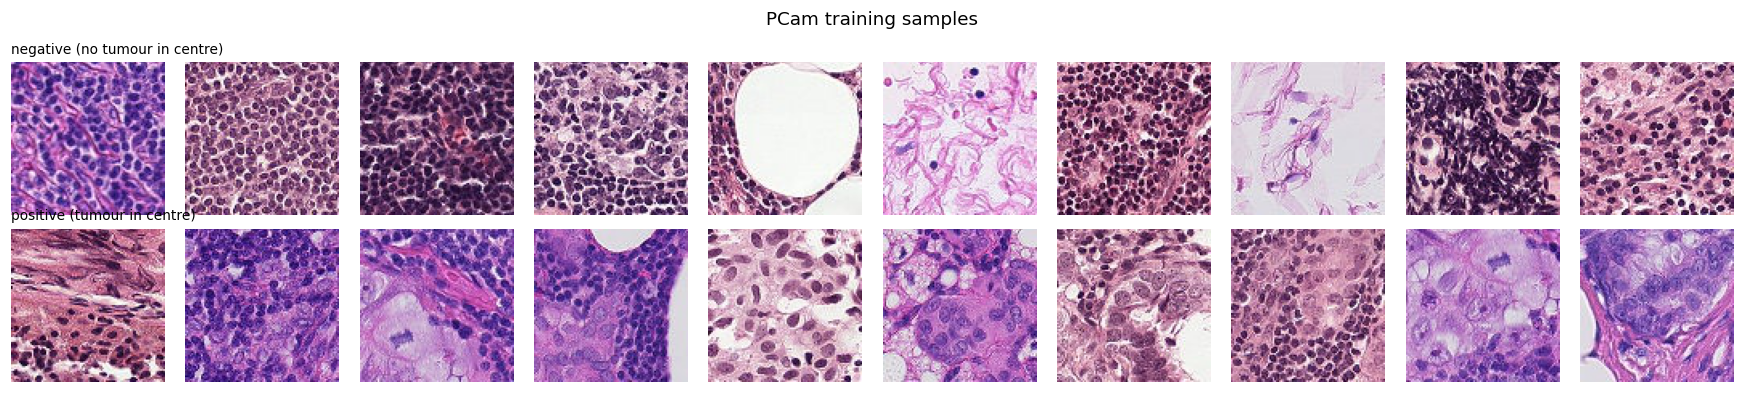

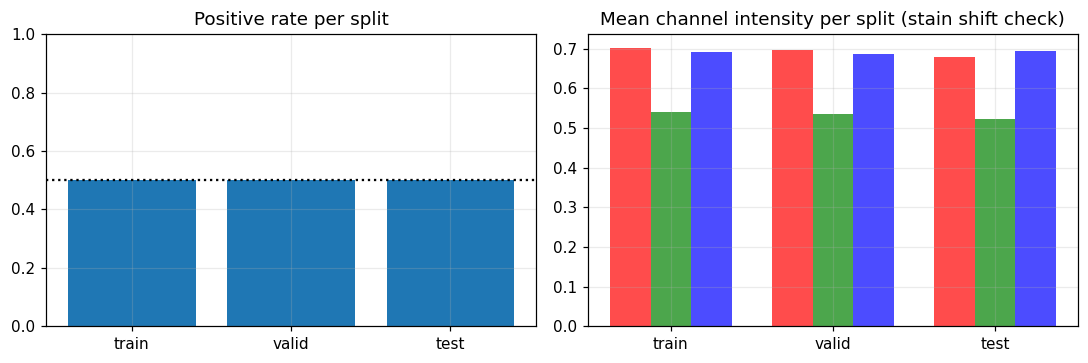

In [4]:
# @title 3 · Dataset statistics + figures
Xm = {s: np.load(LOCAL / f'{s}_x.npy', mmap_mode='r') for s in SPLITS}
Y = {s: np.load(DIRS['labels'] / f'{s}_y.npy').astype(np.int64) for s in SPLITS}

rng = np.random.default_rng(0)
rows = []
for s in SPLITS:
    idx = np.sort(rng.choice(len(Y[s]), 5000, replace=False))
    sample = Xm[s][idx].astype(np.float32) / 255
    rows.append(dict(split=s, n=len(Y[s]), positives=int(Y[s].sum()), pos_rate=round(float(Y[s].mean()), 4),
                     meanR=sample[..., 0].mean(), meanG=sample[..., 1].mean(), meanB=sample[..., 2].mean(),
                     stdR=sample[..., 0].std(), stdG=sample[..., 1].std(), stdB=sample[..., 2].std()))
stats = pd.DataFrame(rows).round(4)
display(stats)
stats.to_csv(DIRS['results'] / 'dataset_stats.csv', index=False)

fig, ax = plt.subplots(2, 10, figsize=(16, 3.6))
for r, c in enumerate([0, 1]):
    ids = rng.choice(np.where(Y['train'] == c)[0], 10, replace=False)
    for j, i in enumerate(np.sort(ids)):
        ax[r, j].imshow(Xm['train'][i]); ax[r, j].axis('off')
    ax[r, 0].set_title(['negative (no tumour in centre)', 'positive (tumour in centre)'][c], loc='left', fontsize=9)
plt.suptitle('PCam training samples'); plt.tight_layout(); savefig('01_samples'); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].bar(stats.split, stats.pos_rate); ax[0].axhline(.5, c='k', ls=':'); ax[0].set_ylim(0, 1); ax[0].set_title('Positive rate per split')
w = .25
for k, ch in enumerate('RGB'):
    ax[1].bar(np.arange(3) + (k - 1) * w, stats[f'mean{ch}'], w, color=ch.lower(), alpha=.7)
ax[1].set_xticks(range(3)); ax[1].set_xticklabels(stats.split); ax[1].set_title('Mean channel intensity per split (stain shift check)')
plt.tight_layout(); savefig('02_split_stats'); plt.show()

## 4 · Frozen-encoder feature extraction (checkpointed in chunks)
Encoders are frozen, so each image is embedded **once**; every later experiment (12 label-budget × seed × head combinations per encoder) runs on cached features in seconds. Features are saved to Drive in chunks of 16,384 images: if the runtime dies, re-running the cell resumes at the first missing chunk. Images are bilinearly upsampled 96→224 to match the encoders' pre-training resolution.

In [5]:
# @title 4 · Extract & cache features (resumable, time-boxed)
import timm
if not all((LOCAL / f'.done_{s}').exists() for s in SPLITS): ensure_images()

def build_encoder(timm_name):
    m = timm.create_model(timm_name, pretrained=True, num_classes=0).eval().cuda()
    cfg = timm.data.resolve_data_config({}, model=m)
    for p in m.parameters(): p.requires_grad_(False)
    return m.to(memory_format=torch.channels_last), cfg['mean'], cfg['std']

@torch.no_grad()
def extract(model, mean, std, x_u8):
    mean = torch.tensor(mean, device='cuda').view(1, 3, 1, 1); std = torch.tensor(std, device='cuda').view(1, 3, 1, 1)
    out = []
    for i in range(0, len(x_u8), CFG['bs']):
        xb = torch.from_numpy(np.ascontiguousarray(x_u8[i:i + CFG['bs']])).cuda(non_blocking=True)
        xb = xb.permute(0, 3, 1, 2).float() / 255
        xb = F.interpolate(xb, size=CFG['img_size'], mode='bilinear', align_corners=False)
        xb = ((xb - mean) / std).contiguous(memory_format=torch.channels_last)
        with torch.autocast('cuda', dtype=torch.float16):
            f = model(xb)
        out.append(f.float().half().cpu())
    return torch.cat(out).numpy()

def feat_dir(m, s):
    d = DIRS['features'] / m / s; d.mkdir(parents=True, exist_ok=True); return d

budget, stopped = Budget(), False
for mname, tname in CFG['models'].items():
    model = None
    for split in ['valid', 'test', 'train']:
        Xs = np.load(LOCAL / f'{split}_x.npy', mmap_mode='r'); n = len(Xs)
        nch = int(np.ceil(n / CFG['chunk']))
        todo = [i for i in range(nch) if not (feat_dir(mname, split) / f'chunk_{i:04d}.npy').exists()]
        if not todo: continue
        if model is None: model, mean, std = build_encoder(tname)
        t0 = time.time()
        for i in todo:
            if budget.expired(): stopped = True; break
            a, b = i * CFG['chunk'], min(n, (i + 1) * CFG['chunk'])
            atomic_save_npy(feat_dir(mname, split) / f'chunk_{i:04d}.npy', extract(model, mean, std, Xs[a:b]))
        print(f'{mname:9s} {split:5s} {len(todo)} chunks in {time.time() - t0:5.0f}s')
        if stopped: break
    del model; gc.collect(); torch.cuda.empty_cache()
    if stopped: break
print('PAUSED by time budget: re-run this cell to resume.' if stopped else 'All features extracted and saved to Drive.')

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

resnet50  valid 2 chunks in    36s
resnet50  test  2 chunks in    35s
resnet50  train 16 chunks in   322s


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

vit_b16   valid 2 chunks in    94s
vit_b16   test  2 chunks in    94s
vit_b16   train 16 chunks in   740s
All features extracted and saved to Drive.


## 5 · Toolkit: heads, metrics, calibration
Definitions only (runs in seconds). **Calibration metrics.** ECE = weighted gap between confidence and accuracy over 15 confidence bins on [0.5, 1] (top-label ECE); Brier and NLL are proper scoring rules. **Temperature scaling** fits one scalar *T* on the (budget-sized) validation subset and rescales logits: it can fix over/under-confidence but, in the binary case, never changes the ranking of predictions.

In [15]:

# @title 5 · Toolkit (heads, metrics, calibration, validation-only selection)

from sklearn.metrics import (
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    accuracy_score,
    confusion_matrix
)

Y = {
    s: np.load(DIRS['labels'] / f'{s}_y.npy').astype(np.int64)
    for s in SPLITS
}

def load_feats(m, s):
    d = feat_dir(m, s)
    fs = sorted(d.glob('chunk_*.npy'))

    expected = int(np.ceil(len(Y[s]) / CFG['chunk']))
    assert len(fs) == expected, (
        f'{m}/{s}: incomplete features. '
        'Re-run Cell 4.'
    )

    X = np.concatenate([np.load(f) for f in fs])
    assert len(X) == len(Y[s])

    return X


def softmax_np(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)


def ece_score(p1, y, n_bins=15):
    probs = np.stack([1 - p1, p1], axis=1)
    conf = probs.max(axis=1)
    correct = (probs.argmax(axis=1) == y).astype(float)

    edges = np.linspace(0.5, 1.0, n_bins + 1)
    bins = np.clip(
        np.digitize(conf, edges[1:-1]),
        0,
        n_bins - 1
    )

    ece = 0.0

    for k in range(n_bins):
        mask = bins == k

        if mask.any():
            ece += mask.mean() * abs(
                correct[mask].mean() - conf[mask].mean()
            )

    return float(ece)


def all_metrics(logits, y):
    p = softmax_np(logits)
    p1 = p[:, 1]
    pred = p.argmax(axis=1)

    return {
        'acc': accuracy_score(y, pred),
        'macro_f1': f1_score(y, pred, average='macro'),
        'bal_acc': balanced_accuracy_score(y, pred),
        'auroc': roc_auc_score(y, p1),
        'ece': ece_score(p1, y),
        'brier': float(np.mean((p1 - y) ** 2)),
        'nll': float(
            -np.mean(np.log(p[np.arange(len(y)), y] + 1e-12))
        )
    }


def fit_temperature(logits, y):
    z = torch.tensor(logits, dtype=torch.float32)
    targets = torch.tensor(y, dtype=torch.long)

    logT = torch.zeros(1, requires_grad=True)

    optimizer = torch.optim.LBFGS(
        [logT],
        lr=0.1,
        max_iter=100
    )

    def closure():
        optimizer.zero_grad()
        loss = F.cross_entropy(z / logT.exp(), targets)
        loss.backward()
        return loss

    optimizer.step(closure)

    return float(logT.detach().exp().clamp(0.05, 20.0))


def sample_nested(y, seed):
    rng = np.random.default_rng(seed)

    i0 = rng.permutation(np.where(y == 0)[0])
    i1 = rng.permutation(np.where(y == 1)[0])

    return i0, i1


def take(i0, i1, fraction):
    return np.concatenate([
        i0[:int(round(len(i0) * fraction))],
        i1[:int(round(len(i1) * fraction))]
    ])


def split_validation(y, seed, fraction):
    """
    Three independent validation subsets:
    60%: early stopping
    20%: model selection
    20%: temperature calibration
    """

    i0, i1 = sample_nested(y, seed)

    fit_idx = []
    select_idx = []
    cal_idx = []

    for indices in [i0, i1]:
        n = len(indices)

        n_fit = int(0.60 * n)
        n_select = int(0.20 * n)

        fit_idx.extend(indices[:n_fit])
        select_idx.extend(
            indices[n_fit:n_fit + n_select]
        )
        cal_idx.extend(
            indices[n_fit + n_select:]
        )

    fit_idx = np.sort(
        np.concatenate([np.asarray(fit_idx)[:int(round(len(i0)*fraction))],
                        np.asarray(fit_idx)[len(i0):][:int(round(len(i1)*fraction))]])
    )

    # Rebuild nested budget subsets before splitting
    budget_idx = take(i0, i1, fraction)

    rng = np.random.default_rng(seed + 999)
    fit_parts, select_parts, cal_parts = [], [], []

    for label in [0, 1]:
        ids = budget_idx[y[budget_idx] == label]
        ids = rng.permutation(ids)

        n_fit = int(0.60 * len(ids))
        n_select = int(0.20 * len(ids))

        fit_parts.extend(ids[:n_fit])
        select_parts.extend(ids[n_fit:n_fit+n_select])
        cal_parts.extend(ids[n_fit+n_select:])

    return (
        np.sort(fit_parts),
        np.sort(select_parts),
        np.sort(cal_parts)
    )


def make_head(kind, d):
    if kind == 'linear':
        return nn.Linear(d, 2)

    return nn.Sequential(
        nn.Linear(d, 512),
        nn.GELU(),
        nn.Dropout(0.3),
        nn.Linear(512, 2)
    )


@torch.no_grad()
def predict(model, X, mu, sd, bs=8192):
    model.eval()

    # Convert NumPy features to a PyTorch tensor if necessary
    if isinstance(X, np.ndarray):
        X = torch.from_numpy(X)

    X = X.float()
    outputs = []

    for i in range(0, len(X), bs):
        xb = (X[i:i+bs].to(mu.device) - mu) / sd
        outputs.append(model(xb).float().cpu())

    return torch.cat(outputs).numpy()


def train_head(
    Xtr, ytr, Xva, yva, kind, seed,
    max_epochs=60, patience=8,
    lr=1e-3, wd=1e-2, bs=512
):
    # Early stopping uses validation FIT subset only.

    seed_everything(seed)

    mu = Xtr.float().mean(0, keepdim=True)
    sd = Xtr.float().std(0, keepdim=True) + 1e-6

    model = make_head(kind, Xtr.shape[1]).cuda()

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=wd
    )

    best_loss = float('inf')
    best_state = None
    best_epoch = 0
    patience_count = 0

    n = len(Xtr)

    for epoch in range(max_epochs):

        model.train()
        permutation = torch.randperm(n, device='cuda')

        for i in range(0, n, bs):
            idx = permutation[i:i+bs]

            logits = model(
                (Xtr[idx].float() - mu) / sd
            )

            loss = F.cross_entropy(logits, ytr[idx])

            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()

        model.eval()

        with torch.no_grad():
            val_logits = model(
                (Xva.float() - mu) / sd
            )

            val_loss = F.cross_entropy(
                val_logits,
                yva
            ).item()

        if val_loss < best_loss - 1e-4:
            best_loss = val_loss
            patience_count = 0
            best_epoch = epoch + 1

            best_state = {
                k: v.detach().clone()
                for k, v in model.state_dict().items()
            }

        else:
            patience_count += 1

            if patience_count >= patience:
                break

    model.load_state_dict(best_state)

    return model, mu, sd, best_epoch


# New results file: keeps old experimental results separate.
RUNS = DIRS['results'] / 'runs_validation_only.jsonl'


def done_keys():
    return {
        (
            r['model'],
            r['head'],
            round(r['fraction'], 2),
            r['seed']
        )
        for r in read_jsonl(RUNS)
    }


def record_run(
    model_name,
    head,
    fraction,
    seed,
    logits_select,
    y_select,
    logits_cal,
    y_cal,
    model,
    mu,
    sd,
    extra
):
    """
    IMPORTANT:
    This function never loads or evaluates the test set.

    Selection metrics: validation selection subset.
    Temperature fitting: independent validation calibration subset.
    """

    T = fit_temperature(logits_cal, y_cal)

    raw = all_metrics(logits_select, y_select)
    calibrated = all_metrics(logits_select / T, y_select)

    rec = dict(
        model=model_name,
        head=head,
        fraction=fraction,
        seed=seed,
        T=T,

        **{
            f'val_{k}': v
            for k, v in raw.items()
        },

        **{
            f'val_ts_{k}': v
            for k, v in calibrated.items()
        },

        **extra
    )

    # Save trained head for final test evaluation.
    checkpoint_dir = DIRS['ckpt'] / 'validation_only'
    checkpoint_dir.mkdir(parents=True, exist_ok=True)

    checkpoint_path = (
        checkpoint_dir /
        f'{model_name}_{head}_{fraction:.2f}_{seed}.pt'
    )

    torch.save({
        'model': model_name,
        'head': head,
        'fraction': fraction,
        'seed': seed,
        'state_dict': {
            k: v.detach().cpu()
            for k, v in model.state_dict().items()
        },
        'mu': mu.detach().cpu(),
        'sd': sd.detach().cpu(),
        'temperature': T
    }, checkpoint_path)

    log_jsonl(RUNS, rec)

    return rec


print('Validation-only toolkit ready.')
print('Test set is not evaluated in this cell.')
print('Results file:', RUNS)


Validation-only toolkit ready.
Test set is not evaluated in this cell.
Results file: /content/drive/MyDrive/pcam_project/results/runs_validation_only.jsonl


In [7]:

# Verification: PCam project files and cached features

print("GPU:", torch.cuda.get_device_name(0))
print("\nFeature verification:")

for model in CFG['models']:
    for split in SPLITS:
        X = load_feats(model, split)
        print(
            f"{model:10s} | {split:5s} | "
            f"shape={X.shape} | dtype={X.dtype}"
        )

print("\nDrive directories:")
for name, path in DIRS.items():
    print(name, ":", path.exists())

print("\nToolkit functions:")
for name in [
    "train_head",
    "split_validation",
    "fit_temperature",
    "all_metrics",
    "record_run"
]:
    print(name, ":", callable(globals().get(name)))

print("\nVERIFICATION COMPLETED")


GPU: Tesla T4

Feature verification:
resnet50   | train | shape=(262144, 2048) | dtype=float16
resnet50   | valid | shape=(32768, 2048) | dtype=float16
resnet50   | test  | shape=(32768, 2048) | dtype=float16
vit_b16    | train | shape=(262144, 768) | dtype=float16
vit_b16    | valid | shape=(32768, 768) | dtype=float16
vit_b16    | test  | shape=(32768, 768) | dtype=float16

Drive directories:
labels : True
features : True
results : True
preds : True
figures : True
ckpt : True
logs : True

Toolkit functions:
train_head : True
split_validation : True
fit_temperature : True
all_metrics : True
record_run : True

VERIFICATION COMPLETED


## 6 · Label-budget experiments (encoder × head × fraction × seed)
48 runs on cached features (2 encoders × 2 heads × 4 fractions × 3 seeds). Each finished run is appended to `results/runs.jsonl` and its test logits saved to `preds/`; re-running the cell skips completed runs.

In [9]:

# @title 6 · Run the label-budget grid (validation-only, resumable)

budget, stopped = Budget(), False

done = done_keys()

total = (
    len(CFG['models'])
    * len(CFG['heads'])
    * len(CFG['fractions'])
    * len(CFG['seeds'])
)

print(f'{len(done)} runs already done / {total}')

for mname in CFG['models']:

    todo = [
        (h, f, seed)
        for seed in CFG['seeds']
        for f in CFG['fractions']
        for h in CFG['heads']
        if (mname, h, round(f, 2), seed) not in done
    ]

    if not todo:
        continue

    # Load TRAIN and VALID features only.
    # TEST features are deliberately not loaded.
    Ftr = torch.from_numpy(load_feats(mname, 'train')).cuda()
    Fva = torch.from_numpy(load_feats(mname, 'valid')).cuda()

    for h, f, seed in todo:

        if budget.expired():
            stopped = True
            break

        t0 = time.time()

        # 1. Select nested training subset
        i0, i1 = sample_nested(Y['train'], seed)
        tr = take(i0, i1, f)

        # 2. Divide validation data into independent subsets
        fit_idx, select_idx, cal_idx = split_validation(
            Y['valid'], seed + 1000, f
        )

        # Convert indices to GPU tensors
        tr_idx = torch.from_numpy(tr).long().cuda()
        fit_gpu = torch.from_numpy(fit_idx).long().cuda()

        # Training labels
        ytr = torch.from_numpy(
            Y['train'][tr]
        ).long().cuda()

        # Validation subsets
        Xfit = Fva[fit_gpu]
        yfit = torch.from_numpy(
            Y['valid'][fit_idx]
        ).long().cuda()

        # 3. Train with early stopping on validation FIT subset
        model, mu, sd, ep = train_head(
            Ftr[tr_idx],
            ytr,
            Xfit,
            yfit,
            h,
            seed
        )

        # 4. Predict on independent validation subsets
        Xselect = Fva[
            torch.from_numpy(select_idx).long().cuda()
        ]

        Xcal = Fva[
            torch.from_numpy(cal_idx).long().cuda()
        ]

        logits_select = predict(model, Xselect, mu, sd)
        logits_cal = predict(model, Xcal, mu, sd)

        y_select = Y['valid'][select_idx]
        y_cal = Y['valid'][cal_idx]

        # 5. Save results using validation data only
        rec = record_run(
            model_name=mname,
            head=h,
            fraction=f,
            seed=seed,
            logits_select=logits_select,
            y_select=y_select,
            logits_cal=logits_cal,
            y_cal=y_cal,
            model=model,
            mu=mu,
            sd=sd,
            extra=dict(
                n_train=len(tr),
                n_val_fit=len(fit_idx),
                n_val_select=len(select_idx),
                n_val_cal=len(cal_idx),
                best_epoch=ep,
                secs=time.time() - t0
            )
        )

        print(
            f'{mname:8s} {h:6s} '
            f'f={f:.2f} seed={seed} '
            f'n={len(tr):6d} | '
            f'VAL F1={rec["val_macro_f1"]:.4f} '
            f'VAL AUROC={rec["val_auroc"]:.4f} '
            f'ECE={rec["val_ece"]:.3f}'
            f'->{rec["val_ts_ece"]:.3f} '
            f'T={rec["T"]:.2f} '
            f'({rec["secs"]:.0f}s)'
        )

        # Release GPU memory
        del model, mu, sd
        gc.collect()
        torch.cuda.empty_cache()

    del Ftr, Fva
    gc.collect()
    torch.cuda.empty_cache()

    if stopped:
        break

print(
    'PAUSED by time budget: re-run this cell to resume.'
    if stopped
    else 'Grid complete.'
)

print('Test set has NOT been used for model selection or evaluation.')


0 runs already done / 48
resnet50 linear f=0.10 seed=0 n= 26214 | VAL F1=0.8560 VAL AUROC=0.9430 ECE=0.046->0.040 T=1.47 (1s)
resnet50 mlp    f=0.10 seed=0 n= 26214 | VAL F1=0.8444 VAL AUROC=0.9348 ECE=0.051->0.037 T=1.40 (1s)
resnet50 linear f=0.25 seed=0 n= 65536 | VAL F1=0.8468 VAL AUROC=0.9409 ECE=0.033->0.031 T=1.07 (2s)
resnet50 mlp    f=0.25 seed=0 n= 65536 | VAL F1=0.8453 VAL AUROC=0.9393 ECE=0.045->0.023 T=1.32 (2s)
resnet50 linear f=0.50 seed=0 n=131072 | VAL F1=0.8457 VAL AUROC=0.9277 ECE=0.025->0.015 T=1.12 (3s)
resnet50 mlp    f=0.50 seed=0 n=131072 | VAL F1=0.8541 VAL AUROC=0.9296 ECE=0.033->0.023 T=1.20 (3s)
resnet50 linear f=1.00 seed=0 n=262144 | VAL F1=0.8575 VAL AUROC=0.9380 ECE=0.035->0.013 T=1.28 (8s)
resnet50 mlp    f=1.00 seed=0 n=262144 | VAL F1=0.8402 VAL AUROC=0.9420 ECE=0.057->0.022 T=1.49 (7s)
resnet50 linear f=0.10 seed=1 n= 26214 | VAL F1=0.8439 VAL AUROC=0.9282 ECE=0.059->0.045 T=1.43 (2s)
resnet50 mlp    f=0.10 seed=1 n= 26214 | VAL F1=0.8350 VAL AUROC=0

In [11]:
from pathlib import Path
import json

base = Path("/content/drive/MyDrive/pcam_project")

print("=== CHECKPOINT FILES ===")
for p in base.rglob("*"):
    if p.is_file() and p.suffix in [".pt", ".pth", ".pkl"]:
        print(p, f"({p.stat().st_size / 1024**2:.2f} MB)")

print("\n=== RESULT RECORD EXAMPLE ===")
results_file = base / "results" / "runs_validation_only.jsonl"

with open(results_file, "r") as f:
    records = [json.loads(line) for line in f if line.strip()]

print("Total records:", len(records))
print("First record:")
print(json.dumps(records[0], indent=2))

=== CHECKPOINT FILES ===
/content/drive/MyDrive/pcam_project/ckpt/validation_only/resnet50_linear_0.10_0.pt (0.03 MB)
/content/drive/MyDrive/pcam_project/ckpt/validation_only/resnet50_mlp_0.10_0.pt (4.02 MB)
/content/drive/MyDrive/pcam_project/ckpt/validation_only/resnet50_linear_0.25_0.pt (0.03 MB)
/content/drive/MyDrive/pcam_project/ckpt/validation_only/resnet50_mlp_0.25_0.pt (4.02 MB)
/content/drive/MyDrive/pcam_project/ckpt/validation_only/resnet50_linear_0.50_0.pt (0.03 MB)
/content/drive/MyDrive/pcam_project/ckpt/validation_only/resnet50_mlp_0.50_0.pt (4.02 MB)
/content/drive/MyDrive/pcam_project/ckpt/validation_only/resnet50_linear_1.00_0.pt (0.03 MB)
/content/drive/MyDrive/pcam_project/ckpt/validation_only/resnet50_mlp_1.00_0.pt (4.02 MB)
/content/drive/MyDrive/pcam_project/ckpt/validation_only/resnet50_linear_0.10_1.pt (0.03 MB)
/content/drive/MyDrive/pcam_project/ckpt/validation_only/resnet50_mlp_0.10_1.pt (4.02 MB)
/content/drive/MyDrive/pcam_project/ckpt/validation_only/res

## 7 · Results: performance vs. label budget

macro_f1          bal_acc  \
model       head   fraction                                     
cnn_scratch full   0.10         0.8796 (n=1)     0.8796 (n=1)   
                   0.25         0.8942 (n=1)     0.8944 (n=1)   
                   0.50         0.9110 (n=1)     0.9112 (n=1)   
                   1.00         0.9070 (n=1)     0.9071 (n=1)   
resnet50    linear 0.10      0.8495 ± 0.0061  0.8498 ± 0.0062   
                   0.25      0.8525 ± 0.0049  0.8530 ± 0.0049   
                   0.50      0.8473 ± 0.0016  0.8475 ± 0.0015   
                   1.00      0.8531 ± 0.0076  0.8535 ± 0.0074   
            mlp    0.10      0.8374 ± 0.0061  0.8381 ± 0.0066   
                   0.25      0.8521 ± 0.0069  0.8528 ± 0.0067   
                   0.50      0.8504 ± 0.0050  0.8508 ± 0.0047   
                   1.00      0.8460 ± 0.0099  0.8471 ± 0.0094   
vit_b16     linear 0.10      0.8624 ± 0.0041  0.8626 ± 0.0040   
                   0.25      0.8512 ± 0.0041  0.8514 ± 0.0041   
                   0.50      0.8456 ± 0.0037  0.8458 ± 0.0037   
                   1.00      0.8468 ± 0.0041  0.8471 ± 0.0041   
            mlp    0.10      0.8561 ± 0.0063  0.8564 ± 0.0061   
                   0.25      0.8488 ± 0.0028  0.8495 ± 0.0025   
                   0.50      0.8535 ± 0.0106  0.8540 ± 0.0102   
                   1.00      0.8422 ± 0.0132  0.8431 ± 0.0128   

                                       auroc              ece  \
model       head   fraction                                     
cnn_scratch full   0.10         0.9478 (n=1)     0.0368 (n=1)   
                   0.25         0.9693 (n=1)     0.0322 (n=1)   
                   0.50         0.9708 (n=1)     0.0279 (n=1)   
                   1.00         0.9638 (n=1)     0.0255 (n=1)   
resnet50    linear 0.10      0.9351 ± 0.0074  0.0456 ± 0.0139   
                   0.25      0.9401 ± 0.0011  0.0330 ± 0.0001   
                   0.50      0.9317 ± 0.0036  0.0300 ± 0.0084   
                   1.00      0.9349 ± 0.0061  0.0345 ± 0.0022   
            mlp    0.10      0.9332 ± 0.0025  0.0504 ± 0.0041   
                   0.25      0.9411 ± 0.0022  0.0414 ± 0.0033   
                   0.50      0.9331 ± 0.0039  0.0456 ± 0.0114   
                   1.00      0.9396 ± 0.0031  0.0537 ± 0.0093   
vit_b16     linear 0.10      0.9407 ± 0.0060  0.0382 ± 0.0061   
                   0.25      0.9335 ± 0.0058  0.0388 ± 0.0048   
                   0.50      0.9308 ± 0.0053  0.0318 ± 0.0044   
                   1.00      0.9295 ± 0.0031  0.0289 ± 0.0045   
            mlp    0.10      0.9451 ± 0.0031  0.0492 ± 0.0112   
                   0.25      0.9416 ± 0.0030  0.0560 ± 0.0103   
                   0.50      0.9375 ± 0.0057  0.0497 ± 0.0078   
                   1.00      0.9318 ± 0.0068  0.0551 ± 0.0111   

                                      ts_ece            brier  \
model       head   fraction                                     
cnn_scratch full   0.10         0.0353 (n=1)     0.1835 (n=1)   
                   0.25         0.0183 (n=1)     0.1482 (n=1)   
                   0.50         0.0130 (n=1)     0.1313 (n=1)   
                   1.00         0.0070 (n=1)     0.1420 (n=1)   
resnet50    linear 0.10      0.0436 ± 0.0031  0.1064 ± 0.0054   
                   0.25      0.0256 ± 0.0052  0.1018 ± 0.0008   
                   0.50      0.0185 ± 0.0033  0.1074 ± 0.0018   
                   1.00      0.0136 ± 0.0032  0.1048 ± 0.0055   
            mlp    0.10      0.0407 ± 0.0059  0.1107 ± 0.0010   
                   0.25      0.0194 ± 0.0046  0.1035 ± 0.0029   
                   0.50      0.0198 ± 0.0043  0.1081 ± 0.0024   
                   1.00      0.0146 ± 0.0062  0.1104 ± 0.0053   
vit_b16     linear 0.10      0.0372 ± 0.0060  0.0985 ± 0.0041   
                   0.25      0.0278 ± 0.0041  0.1069 ± 0.0054   
                   0.50      0.0216 ± 0.0028  0.1084 ± 0.0036   
                   1.00      0.0148 ± 0.0012  0.1098 ± 0.0027   
    

Summary saved to: /content/drive/MyDrive/pcam_project/results/summary_mean_std.csv

Label efficiency:


F1@10%  F1@100%  retained_%
model       head                               
cnn_scratch full    0.8796   0.9070     96.9727
resnet50    linear  0.8495   0.8531     99.5819
            mlp     0.8374   0.8460     98.9863
vit_b16     linear  0.8624   0.8468    101.8423
            mlp     0.8561   0.8422    101.6495


Paired Macro-F1 gap (ViT - ResNet):


mean     std  count
head   fraction                       
linear 0.10      0.0129  0.0094      3
       0.25     -0.0013  0.0088      3
       0.50     -0.0016  0.0052      3
       1.00     -0.0062  0.0054      3
mlp    0.10      0.0186  0.0022      3
       0.25     -0.0034  0.0094      3
       0.50      0.0031  0.0154      3
       1.00     -0.0038  0.0070      3

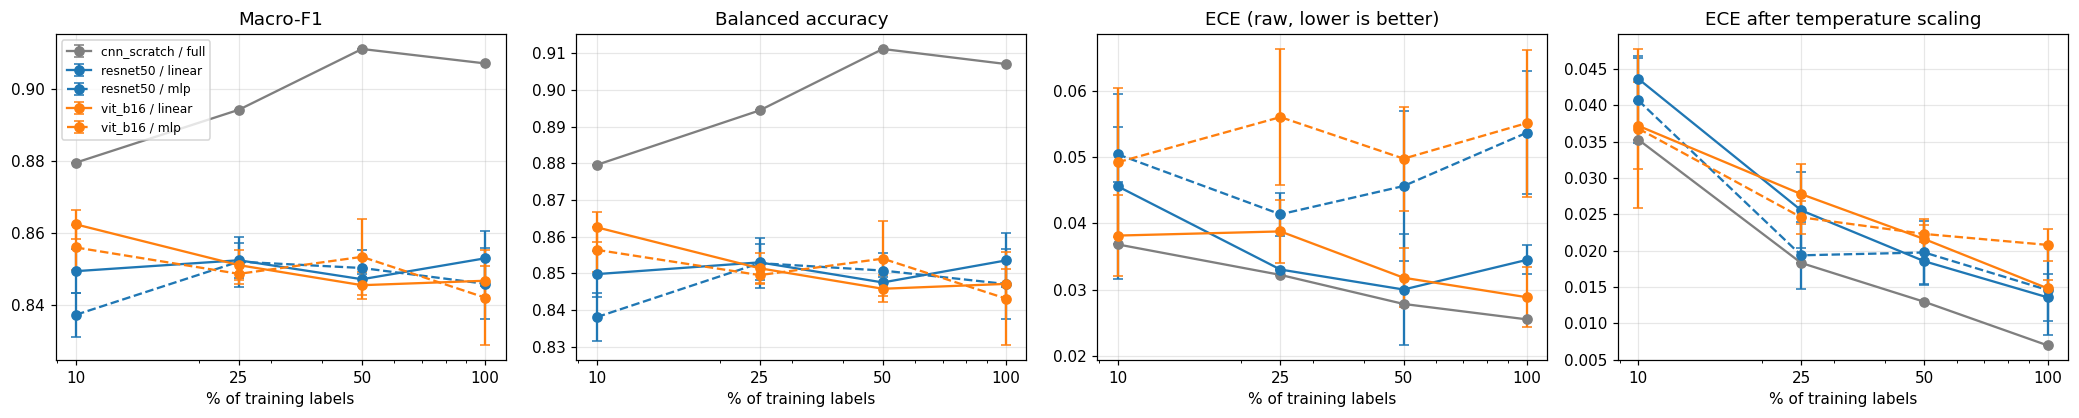


Title 7 completed.
All tables and curves use validation results only.
The test set was not used in this aggregation.


In [20]:

# @title 7 · Aggregate tables + learning curves (validation-only)

df = pd.DataFrame(read_jsonl(RUNS))
df["fraction"] = df["fraction"].round(2)

METRICS = [
    "val_macro_f1",
    "val_bal_acc",
    "val_auroc",
    "val_ece",
    "val_ts_ece",
    "val_brier",
    "val_nll"
]

# Keep only records with the required validation metrics
df = df.dropna(subset=METRICS)

# 1. Aggregate mean and standard deviation across available seeds
group_cols = ["model", "head", "fraction"]
g = df.groupby(group_cols)[METRICS]

agg = g.agg(["mean", "std"])
agg["n_seeds"] = df.groupby(group_cols).size()

summary_path = DIRS["results"] / "summary_mean_std.csv"
agg.to_csv(summary_path)

# Display mean ± standard deviation and number of seeds
pretty = pd.DataFrame(index=agg.index)

for metric in METRICS:
    mean = agg[(metric, "mean")]
    std = agg[(metric, "std")]

    pretty[metric.replace("val_", "")] = [
        f"{m:.4f} ± {s:.4f}" if pd.notna(s) else f"{m:.4f} (n=1)"
        for m, s in zip(mean, std)
    ]

pretty["n_seeds"] = agg["n_seeds"]
display(pretty)

print("Summary saved to:", summary_path)

# 2. Label efficiency: compare 10% and 100% where both exist
f1 = agg[("val_macro_f1", "mean")].unstack("fraction")

if 0.10 in f1.columns and 1.00 in f1.columns:
    eff = pd.DataFrame({
        "F1@10%": f1[0.10],
        "F1@100%": f1[1.00]
    })
    eff["retained_%"] = 100 * eff["F1@10%"] / eff["F1@100%"]
    print("\nLabel efficiency:")
    display(eff.round(4))

# 3. Paired ViT-versus-ResNet comparison
# Only compare matching feature heads, fractions and seeds.
feature_df = df[df["model"].isin(["resnet50", "vit_b16"])]

piv = feature_df.pivot_table(
    index=["head", "fraction", "seed"],
    columns="model",
    values="val_macro_f1"
)

if {"resnet50", "vit_b16"}.issubset(piv.columns):
    paired = piv.dropna(subset=["resnet50", "vit_b16"])
    gap = (
        paired["vit_b16"] - paired["resnet50"]
    ).groupby(["head", "fraction"]).agg(["mean", "std", "count"])

    print("\nPaired Macro-F1 gap (ViT - ResNet):")
    display(gap.round(4))

# 4. Validation learning curves
cols = {
    "resnet50": "tab:blue",
    "vit_b16": "tab:orange",
    "cnn_scratch": "tab:gray"
}

fig, axes = plt.subplots(1, 4, figsize=(19, 3.9))

plots = [
    ("val_macro_f1", "Macro-F1"),
    ("val_bal_acc", "Balanced accuracy"),
    ("val_ece", "ECE (raw, lower is better)"),
    ("val_ts_ece", "ECE after temperature scaling")
]

for ax, (metric, title) in zip(axes, plots):
    for (model_name, head), d in df.groupby(["model", "head"]):
        a = d.groupby("fraction")[metric].agg(["mean", "std", "count"])
        a["std"] = a["std"].fillna(0)

        ax.errorbar(
            a.index * 100,
            a["mean"],
            yerr=a["std"],
            marker="o",
            capsize=3,
            color=cols.get(model_name, "black"),
            linestyle="-" if head in ("linear", "full") else "--",
            label=f"{model_name} / {head}"
        )

    ax.set_xscale("log")
    ax.set_xticks([10, 25, 50, 100])
    ax.set_xticklabels(["10", "25", "50", "100"])
    ax.set_xlabel("% of training labels")
    ax.set_title(title)
    ax.grid(True, alpha=0.3)

axes[0].legend(fontsize=8)
plt.tight_layout()

savefig("03_label_budget_curves")
plt.show()

print("\nTitle 7 completed.")
print("All tables and curves use validation results only.")
print("The test set was not used in this aggregation.")


## 8 · Does confidence reflect reliability? (calibration)
Reliability diagrams for the smallest (10 %) and the full (100 %) label budget, before and after temperature scaling. Points on the diagonal = confidence equals empirical accuracy; 95 % bootstrap CIs on ECE (test set resampled).

Heads selected using validation data: {'resnet50': 'linear', 'vit_b16': 'linear'}


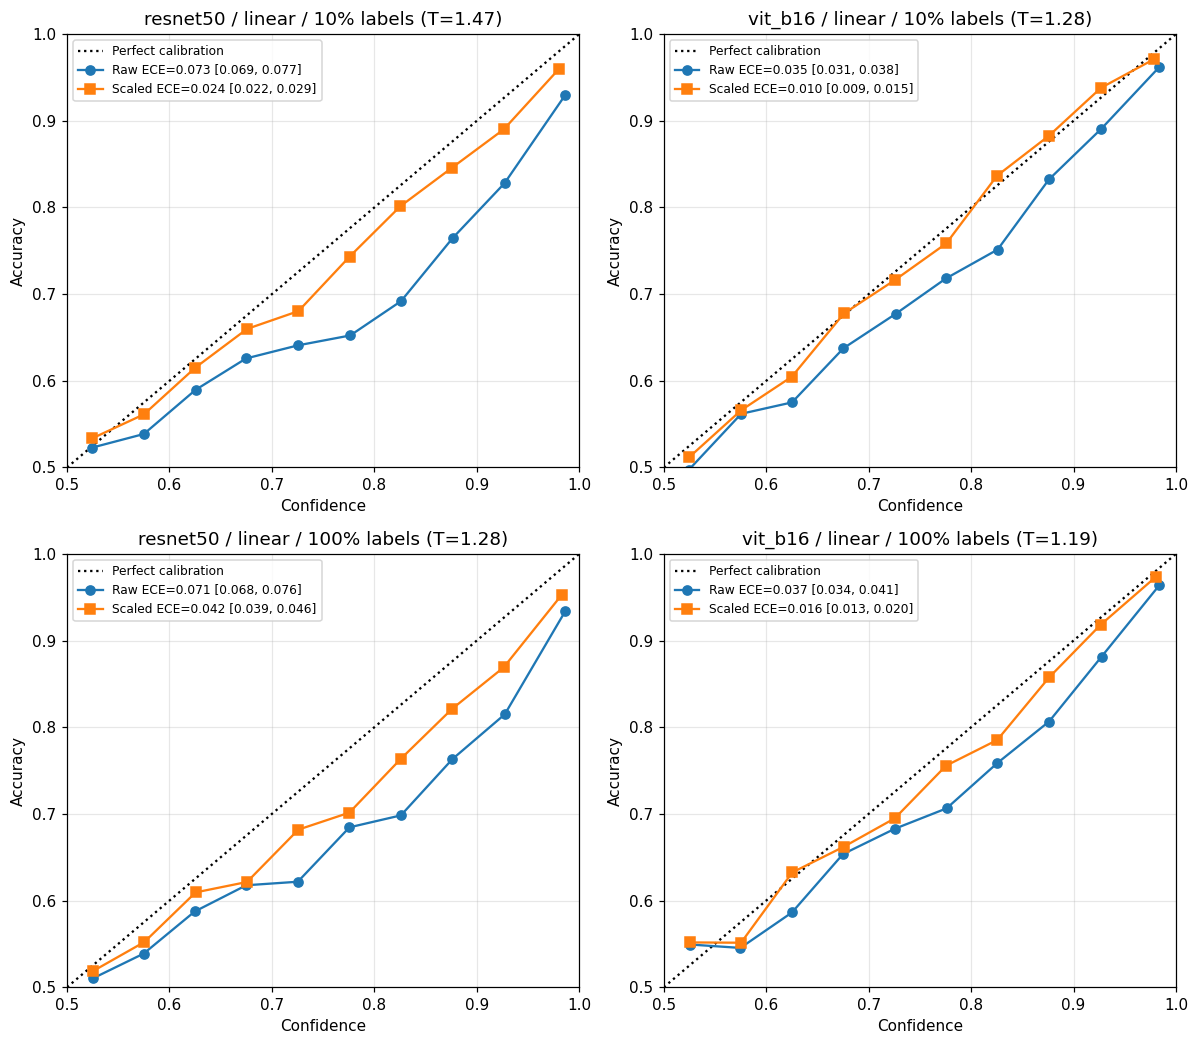

,model,head,fraction,seed,temperature,test_ece_raw,test_ece_raw_ci_low,test_ece_raw_ci_high,test_ece_scaled,test_ece_scaled_ci_low,test_ece_scaled_ci_high
0,resnet50,linear,0.1,0,1.4737,0.0728,0.0691,0.0768,0.0243,0.0219,0.0292
1,vit_b16,linear,0.1,0,1.2754,0.0346,0.0314,0.0384,0.0099,0.0085,0.0149
2,resnet50,linear,1.0,0,1.2818,0.0715,0.0680,0.0756,0.0421,0.0389,0.0465
3,vit_b16,linear,1.0,0,1.1929,0.0369,0.0338,0.0411,0.0157,0.0132,0.0201



Title 8 completed.
Test predictions generated from saved checkpoints.
Calibration table: /content/drive/MyDrive/pcam_project/results/calibration_table.csv


In [16]:

# @title 8 · Reliability diagrams + bootstrap CIs (final test evaluation)

from pathlib import Path

df = pd.DataFrame(read_jsonl(RUNS))
df["fraction"] = df["fraction"].round(2)

feat_models = list(CFG["models"])
FR = [0.10, 1.00]
SEED = 0

# 1. Select the best head for EACH model using validation only.
validation_scores = (
    df[
        df.model.isin(feat_models) &
        (df.fraction == 1.00)
    ]
    .groupby(["model", "head"])["val_macro_f1"]
    .mean()
)

best_heads = (
    validation_scores
    .groupby(level="model")
    .idxmax()
    .map(lambda x: x[1])
    .to_dict()
)

print("Heads selected using validation data:", best_heads)

# 2. Load a trained checkpoint and generate test predictions.
def load_test_logits(model_name, head, fraction, seed):

    checkpoint_path = (
        DIRS["ckpt"] / "validation_only" /
        f"{model_name}_{head}_{fraction:.2f}_{seed}.pt"
    )

    if not checkpoint_path.exists():
        raise FileNotFoundError(checkpoint_path)

    ckpt = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )

    X_test = load_feats(model_name, "test")

    model = make_head(head, X_test.shape[1]).cuda()
    model.load_state_dict(ckpt["state_dict"])

    mu = ckpt["mu"].cuda()
    sd = ckpt["sd"].cuda()

    logits = predict(model, X_test, mu, sd)

    temperature = float(ckpt["temperature"])

    del model, X_test, mu, sd
    torch.cuda.empty_cache()

    return logits, temperature


# 3. Reliability diagram and bootstrap functions.
def rel_bins(p1, y, n_bins=10, min_n=20):

    conf = np.maximum(p1, 1 - p1)
    correct = ((p1 >= 0.5).astype(int) == y)

    bins = np.clip(
        np.digitize(
            conf,
            np.linspace(0.5, 1.0, n_bins + 1)[1:-1]
        ),
        0,
        n_bins - 1
    )

    result = []

    for k in range(n_bins):
        mask = bins == k

        if mask.sum() >= min_n:
            result.append((
                conf[mask].mean(),
                correct[mask].mean()
            ))

    return np.asarray(result)


def boot_ci(fn, p1, y, n=1000, seed=0):

    rng = np.random.default_rng(seed)
    values = []

    for _ in range(n):
        idx = rng.integers(0, len(y), len(y))
        values.append(fn(p1[idx], y[idx]))

    return np.percentile(values, [2.5, 97.5])


# 4. Final test evaluation.
y_test = Y["test"]
rows = []

fig, axes = plt.subplots(
    len(FR),
    len(feat_models),
    figsize=(5.5 * len(feat_models), 4.8 * len(FR)),
    squeeze=False
)

for r, fraction in enumerate(FR):

    for c, model_name in enumerate(feat_models):

        head = best_heads[model_name]

        logits, T = load_test_logits(
            model_name, head, fraction, SEED
        )

        p_raw = softmax_np(logits)[:, 1]
        p_ts = softmax_np(logits / T)[:, 1]

        e_raw = ece_score(p_raw, y_test)
        e_ts = ece_score(p_ts, y_test)

        ci_raw = boot_ci(
            ece_score, p_raw, y_test,
            seed=42
        )

        ci_ts = boot_ci(
            ece_score, p_ts, y_test,
            seed=42
        )

        ax = axes[r, c]

        ax.plot(
            [0.5, 1.0], [0.5, 1.0],
            "k:", label="Perfect calibration"
        )

        for probabilities, label, marker in [
            (
                p_raw,
                f"Raw ECE={e_raw:.3f} "
                f"[{ci_raw[0]:.3f}, {ci_raw[1]:.3f}]",
                "o-"
            ),
            (
                p_ts,
                f"Scaled ECE={e_ts:.3f} "
                f"[{ci_ts[0]:.3f}, {ci_ts[1]:.3f}]",
                "s-"
            )
        ]:

            bins = rel_bins(probabilities, y_test)

            if len(bins):
                ax.plot(
                    bins[:, 0],
                    bins[:, 1],
                    marker,
                    label=label
                )

        ax.set_title(
            f"{model_name} / {head} / "
            f"{int(fraction * 100)}% labels (T={T:.2f})"
        )

        ax.set_xlabel("Confidence")
        ax.set_ylabel("Accuracy")
        ax.set_xlim(0.5, 1.0)
        ax.set_ylim(0.5, 1.0)
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)

        rows.append({
            "model": model_name,
            "head": head,
            "fraction": fraction,
            "seed": SEED,
            "temperature": T,
            "test_ece_raw": e_raw,
            "test_ece_raw_ci_low": ci_raw[0],
            "test_ece_raw_ci_high": ci_raw[1],
            "test_ece_scaled": e_ts,
            "test_ece_scaled_ci_low": ci_ts[0],
            "test_ece_scaled_ci_high": ci_ts[1]
        })

        del logits, p_raw, p_ts
        torch.cuda.empty_cache()

plt.tight_layout()

savefig("04_reliability_diagrams")
plt.show()

# 5. Save calibration results.
calibration_table = pd.DataFrame(rows).round(4)

calibration_path = (
    DIRS["results"] / "calibration_table.csv"
)

calibration_table.to_csv(
    calibration_path,
    index=False
)

display(calibration_table)

print("\nTitle 8 completed.")
print("Test predictions generated from saved checkpoints.")
print("Calibration table:", calibration_path)


## 9 · Error analysis & selective prediction
* Confusion matrices, false-positive / false-negative rates (clinically, FN = missed tumour).
* Is confidence informative about *errors*? AUROC of confidence for detecting mistakes, and **risk–coverage** curves: if the model abstains on its least-confident cases, how fast does the error rate fall?
* Visual inspection of the most confident mistakes. (Temperature scaling does not change rankings, so risk–coverage uses raw confidence.)

Completed: resnet50, 10% labels
Completed: resnet50, 25% labels
Completed: resnet50, 50% labels
Completed: resnet50, 100% labels
Completed: vit_b16, 10% labels
Completed: vit_b16, 25% labels
Completed: vit_b16, 50% labels
Completed: vit_b16, 100% labels


,model,head,fraction,error_rate,FPR,FNR,high_conf_errors_ge90,frac_pred_ge90,err_detect_auroc,AURC,risk_at_90cov,risk_at_80cov
0,resnet50,linear,0.10,0.1903,0.0890,0.2917,902,0.4407,0.7592,0.0798,0.1611,0.1360
1,resnet50,linear,0.25,0.1843,0.0875,0.2812,1201,0.5497,0.7787,0.0706,0.1550,0.1258
2,resnet50,linear,0.50,0.1835,0.0889,0.2783,947,0.4949,0.7774,0.0713,0.1528,0.1246
3,resnet50,linear,1.00,0.1891,0.0794,0.2990,1195,0.5140,0.7652,0.0773,0.1592,0.1324
4,vit_b16,linear,0.10,0.1697,0.1062,0.2333,589,0.4498,0.7920,0.0623,0.1370,0.1091
5,vit_b16,linear,0.25,0.1634,0.1016,0.2252,740,0.4997,0.7890,0.0598,0.1329,0.1042
6,vit_b16,linear,0.50,0.1652,0.1023,0.2281,639,0.4746,0.7921,0.0592,0.1338,0.1062
7,vit_b16,linear,1.00,0.1698,0.1011,0.2385,688,0.4836,0.7883,0.0616,0.1390,0.1117


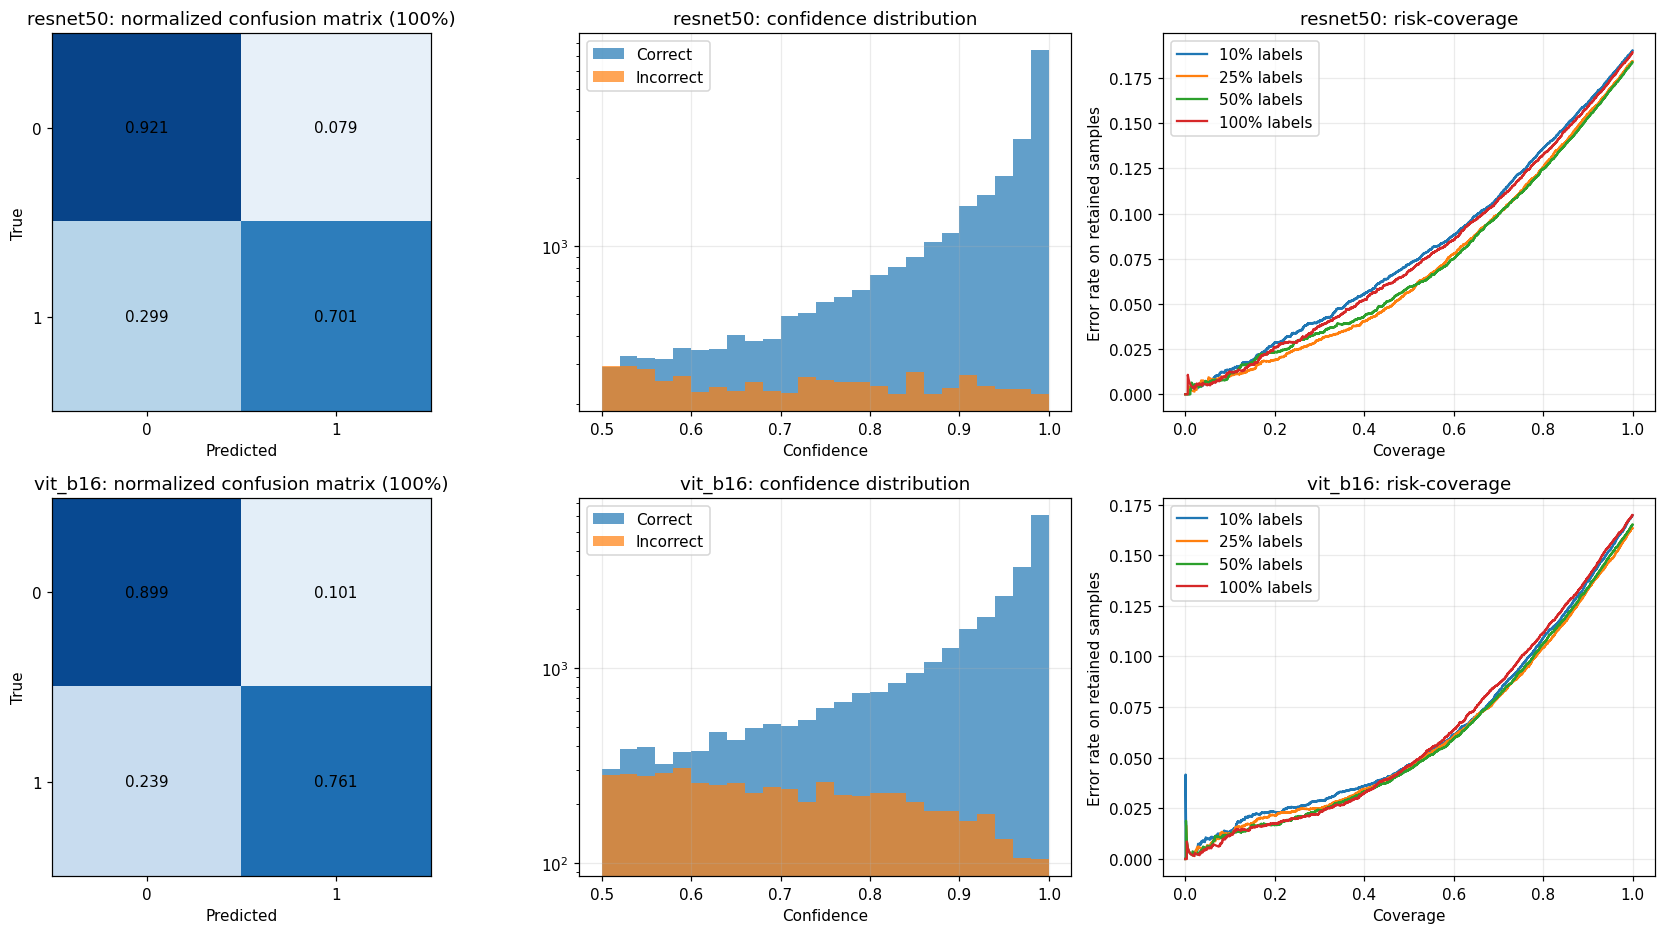

Error analysis saved to: /content/drive/MyDrive/pcam_project/results/error_analysis.csv


In [18]:
# @title 9 · Error analysis, risk-coverage, high-confidence mistakes

def risk_coverage(conf, wrong):
    order = np.argsort(-conf, kind="stable")
    sorted_wrong = wrong[order].astype(float)
    coverage = np.arange(1, len(sorted_wrong) + 1) / len(sorted_wrong)
    risk = np.cumsum(sorted_wrong) / np.arange(1, len(sorted_wrong) + 1)
    return coverage, risk


yte = Y["test"]
fractions = CFG["fractions"]

rows = []
curves = {}

for m in feat_models:
    for f in fractions:

        # Generate predictions from the saved checkpoint
        z, T = load_test_logits(m, best_heads[m], f, SEED)

        # Use temperature-scaled probabilities
        p = softmax_np(z / T)
        pred = p.argmax(axis=1)
        conf = p.max(axis=1)
        wrong = pred != yte

        cov, risk = risk_coverage(conf, wrong)
        curves[(m, f)] = (cov, risk)

        tn, fp, fn, tp = confusion_matrix(
            yte, pred, labels=[0, 1]
        ).ravel()

        n = len(yte)

        err_auroc = (
            roc_auc_score(wrong.astype(int), -conf)
            if len(np.unique(wrong)) == 2 else np.nan
        )

        rows.append({
            "model": m,
            "head": best_heads[m],
            "fraction": f,
            "error_rate": wrong.mean(),
            "FPR": fp / (fp + tn),
            "FNR": fn / (fn + tp),
            "high_conf_errors_ge90": int((wrong & (conf >= 0.90)).sum()),
            "frac_pred_ge90": float((conf >= 0.90).mean()),
            "err_detect_auroc": err_auroc,
            "AURC": np.trapz(risk, cov),
            "risk_at_90cov": risk[int(0.90 * n) - 1],
            "risk_at_80cov": risk[int(0.80 * n) - 1]
        })

        print(f"Completed: {m}, {int(f*100)}% labels")

err = pd.DataFrame(rows).round(4)

err.to_csv(
    DIRS["results"] / "error_analysis.csv",
    index=False
)

display(err)


# Confusion matrices, confidence distributions and risk-coverage curves

fig, axes = plt.subplots(
    len(feat_models), 3,
    figsize=(15.5, 4.3 * len(feat_models)),
    squeeze=False
)

for r, m in enumerate(feat_models):

    z, T = load_test_logits(m, best_heads[m], 1.0, SEED)
    p = softmax_np(z / T)
    pred = p.argmax(axis=1)
    conf = p.max(axis=1)

    # Confusion matrix
    cm = confusion_matrix(yte, pred, normalize="true")

    ax = axes[r, 0]
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    ax.grid(False)

    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:.3f}",
                    ha="center", va="center")

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(f"{m}: normalized confusion matrix (100%)")

    # Confidence distribution
    ax = axes[r, 1]
    bins = np.linspace(0.5, 1.0, 26)

    ax.hist(conf[pred == yte], bins,
            alpha=0.7, label="Correct")
    ax.hist(conf[pred != yte], bins,
            alpha=0.7, label="Incorrect")

    ax.set_yscale("log")
    ax.set_xlabel("Confidence")
    ax.set_title(f"{m}: confidence distribution")
    ax.legend()

    # Risk-coverage curves
    ax = axes[r, 2]

    for f in fractions:
        cov, risk = curves[(m, f)]
        ax.plot(cov, risk, label=f"{int(f*100)}% labels")

    ax.set_xlabel("Coverage")
    ax.set_ylabel("Error rate on retained samples")
    ax.set_title(f"{m}: risk-coverage")
    ax.legend()

plt.tight_layout()
savefig("05_error_analysis")
plt.show()


print("Error analysis saved to:", DIRS["results"] / "error_analysis.csv")

## 10 · (Optional) Reference: small CNN trained from scratch
Answers "does pre-training actually help?" by training the same label budgets with **no** pre-training (one seed, ~8–40 epochs depending on budget so each run sees a similar number of optimisation steps). Checkpointed **every epoch**; time-boxed; resumable. Skip this cell if you are short on time — Cells 11 works without it.

In [19]:
# @title 10 · From-scratch CNN baseline (resumable, time-boxed)

import json
import time
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    log_loss
)
from scipy.optimize import minimize_scalar


# ---------------------------------------------------------
# 1. Prepare images and configuration
# ---------------------------------------------------------

if not (LOCAL / ".done_train").exists():
    ensure_images()

Xm = {
    s: np.load(LOCAL / f"{s}_x.npy", mmap_mode="r")
    for s in SPLITS
}

SC_SEEDS = [0]
SC_BS = 128

# Estimate channel normalization from 10,000 training images
_s = np.sort(
    np.random.default_rng(0).choice(
        len(Y["train"]), 10000, replace=False
    )
)

_x = Xm["train"][_s].astype(np.float32) / 255.0

MEAN = torch.tensor(
    _x.mean((0, 1, 2)), device="cuda"
).view(1, 3, 1, 1)

STD = torch.tensor(
    _x.std((0, 1, 2)), device="cuda"
).view(1, 3, 1, 1)

del _x, _s


# ---------------------------------------------------------
# 2. CNN architecture
# ---------------------------------------------------------

def conv_block(i, o):
    return nn.Sequential(
        nn.Conv2d(i, o, 3, padding=1, bias=False),
        nn.BatchNorm2d(o),
        nn.ReLU(inplace=True),

        nn.Conv2d(o, o, 3, padding=1, bias=False),
        nn.BatchNorm2d(o),
        nn.ReLU(inplace=True),

        nn.MaxPool2d(2)
    )


class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.f = nn.Sequential(
            conv_block(3, 32),
            conv_block(32, 64),
            conv_block(64, 128),
            conv_block(128, 256),
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(0.3)
        )

        self.c = nn.Linear(256, 2)

    def forward(self, x):
        return self.c(self.f(x))


# ---------------------------------------------------------
# 3. Image preprocessing and dataset
# ---------------------------------------------------------

def prep(xb_u8, train):
    x = (
        xb_u8.cuda(non_blocking=True)
        .permute(0, 3, 1, 2)
        .float() / 255.0
    )

    if train:
        if random.random() < 0.5:
            x = x.flip(3)

        if random.random() < 0.5:
            x = x.flip(2)

        x = torch.rot90(
            x, random.randint(0, 3), (2, 3)
        )

        n = x.shape[0]

        x = x * (
            1 + 0.4 * (
                torch.rand(n, 1, 1, 1, device="cuda") - 0.5
            )
        )

        x = x + 0.2 * (
            torch.rand(n, 1, 1, 1, device="cuda") - 0.5
        )

    return (
        (x - MEAN) / STD
    ).contiguous(memory_format=torch.channels_last)


class BatchDS(torch.utils.data.Dataset):
    def __init__(self, path, batches, y):
        self.path = path
        self.batches = batches
        self.y = y
        self.x = None

    def __len__(self):
        return len(self.batches)

    def __getitem__(self, i):
        if self.x is None:
            self.x = np.load(self.path, mmap_mode="r")

        idx = np.sort(self.batches[i])

        return (
            torch.from_numpy(self.x[idx]),
            torch.from_numpy(self.y[idx])
        )


@torch.no_grad()
def eval_logits(model, x_u8, bs=512):
    model.eval()
    out = []

    for i in range(0, len(x_u8), bs):
        xb = torch.from_numpy(
            np.ascontiguousarray(x_u8[i:i + bs])
        )

        with torch.autocast("cuda", dtype=torch.float16):
            logits = model(prep(xb, False))

        out.append(logits.float().cpu())

    return torch.cat(out).numpy()


# ---------------------------------------------------------
# 4. Metrics and temperature calibration
# ---------------------------------------------------------

def scratch_softmax(logits):
    x = logits - logits.max(axis=1, keepdims=True)
    e = np.exp(x)
    return e / e.sum(axis=1, keepdims=True)


def scratch_ece(y, probs, n_bins=15):
    confidence = probs.max(axis=1)
    prediction = probs.argmax(axis=1)
    correct = (prediction == y).astype(float)

    edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0

    for i in range(n_bins):
        mask = (
            (confidence > edges[i]) &
            (confidence <= edges[i + 1])
        )

        if mask.any():
            ece += (
                mask.mean() *
                abs(correct[mask].mean() - confidence[mask].mean())
            )

    return float(ece)


def scratch_fit_temperature(logits, y):
    def objective(log_t):
        temperature = np.exp(log_t)
        probs = scratch_softmax(logits / temperature)

        return log_loss(
            y, probs, labels=[0, 1]
        )

    result = minimize_scalar(
        objective,
        bounds=(-2.3, 2.3),
        method="bounded"
    )

    return float(np.exp(result.x))


def scratch_metrics(y, logits, temperature=1.0):
    probs = scratch_softmax(logits / temperature)
    pred = probs.argmax(axis=1)

    return {
        "macro_f1": float(
            f1_score(y, pred, average="macro")
        ),
        "bal_acc": float(
            balanced_accuracy_score(y, pred)
        ),
        "auroc": float(
            roc_auc_score(y, probs[:, 1])
        ),
        "ece": scratch_ece(y, probs),
        "brier": float(
            np.mean(
                np.sum(
                    (probs - np.eye(2)[y]) ** 2,
                    axis=1
                )
            )
        ),
        "nll": float(
            log_loss(y, probs, labels=[0, 1])
        )
    }


# ---------------------------------------------------------
# 5. Training and checkpointing
# ---------------------------------------------------------

def run_scratch(f, seed, budget):

    key = ("cnn_scratch", "full", round(f, 2), seed)

    if key in done_keys():
        print("  Already completed.")
        return "done"

    seed_everything(seed)

    # Nested training subset
    i0, i1 = sample_nested(Y["train"], seed)
    tr = take(i0, i1, f)

    # Nested validation subset
    v0, v1 = sample_nested(Y["valid"], seed + 1000)
    va = np.sort(take(v0, v1, f))

    # Separate validation into:
    # early stopping / temperature calibration / metric selection
    va_stop, va_temp = train_test_split(
        va,
        test_size=0.40,
        random_state=seed,
        stratify=Y["valid"][va]
    )

    va_temp, va_select = train_test_split(
        va_temp,
        test_size=0.50,
        random_state=seed + 1,
        stratify=Y["valid"][va_temp]
    )

    va_stop = np.sort(va_stop)
    va_temp = np.sort(va_temp)
    va_select = np.sort(va_select)

    spe = int(np.ceil(len(tr) / SC_BS))
    epochs = int(np.clip(np.ceil(5000 / spe), 8, 40))

    model = SmallCNN().cuda().to(
        memory_format=torch.channels_last
    )

    opt = torch.optim.AdamW(
        model.parameters(),
        lr=2e-3,
        weight_decay=1e-2
    )

    sched = torch.optim.lr_scheduler.OneCycleLR(
        opt,
        max_lr=2e-3,
        total_steps=epochs * spe
    )

    scaler = torch.amp.GradScaler("cuda")

    ck = DIRS["ckpt"] / f"scratch_{f:.2f}_{seed}.pt"

    st = {
        "ep": 0,
        "best": float("inf"),
        "best_state": None,
        "hist": []
    }

    # Resume if a checkpoint exists
    if ck.exists():
        c = torch.load(ck, map_location="cuda", weights_only=False)

        model.load_state_dict(c["model"])
        opt.load_state_dict(c["opt"])
        sched.load_state_dict(c["sched"])
        scaler.load_state_dict(c["scaler"])
        st = c["st"]

        print(f'  Resumed at epoch {st["ep"]}/{epochs}')

    Xva_stop = Xm["valid"][va_stop]
    yva_stop = Y["valid"][va_stop]

    t0 = time.time()

    while st["ep"] < epochs:

        if budget.expired():
            print("  Time budget reached; checkpoint saved.")
            return "paused"

        rng = np.random.default_rng(
            seed * 1000 + st["ep"]
        )

        perm = rng.permutation(tr)

        batches = [
            perm[i:i + SC_BS]
            for i in range(0, len(perm), SC_BS)
        ]

        dl = torch.utils.data.DataLoader(
            BatchDS(
                LOCAL / "train_x.npy",
                batches,
                Y["train"]
            ),
            batch_size=None,
            num_workers=2,
            prefetch_factor=2,
            pin_memory=True
        )

        model.train()
        total_loss = 0.0

        for xb, yb in dl:

            opt.zero_grad(set_to_none=True)

            with torch.autocast(
                "cuda", dtype=torch.float16
            ):
                logits = model(prep(xb, True))
                loss = F.cross_entropy(
                    logits, yb.cuda(non_blocking=True)
                )

            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sched.step()

            total_loss += loss.item()

        # Early stopping uses only va_stop
        val_logits = eval_logits(model, Xva_stop)
        val_loss = F.cross_entropy(
            torch.tensor(val_logits),
            torch.tensor(yva_stop)
        ).item()

        if val_loss < st["best"]:
            st["best"] = val_loss
            st["best_state"] = {
                k: v.detach().clone()
                for k, v in model.state_dict().items()
            }

        st["ep"] += 1

        st["hist"].append((
            total_loss / len(batches),
            val_loss
        ))

        torch.save(
            {
                "model": model.state_dict(),
                "opt": opt.state_dict(),
                "sched": sched.state_dict(),
                "scaler": scaler.state_dict(),
                "st": st
            },
            ck
        )

        print(
            f'  f={f:.2f} epoch {st["ep"]}/{epochs} '
            f'train_loss={total_loss / len(batches):.4f} '
            f'val_loss={val_loss:.4f}'
        )

    # -----------------------------------------------------
    # 6. Final validation and test evaluation
    # -----------------------------------------------------

    model.load_state_dict(st["best_state"])
    model.eval()

    # Validation calibration subset
    z_temp = eval_logits(
        model, Xm["valid"][va_temp]
    )
    y_temp = Y["valid"][va_temp]

    temperature = scratch_fit_temperature(
        z_temp, y_temp
    )

    # Independent validation selection subset
    z_select = eval_logits(
        model, Xm["valid"][va_select]
    )
    y_select = Y["valid"][va_select]

    val_raw = scratch_metrics(
        y_select, z_select, 1.0
    )

    val_cal = scratch_metrics(
        y_select, z_select, temperature
    )

    # Test is used only for final evaluation
    z_test = eval_logits(model, Xm["test"])
    y_test = Y["test"]

    test_raw = scratch_metrics(
        y_test, z_test, 1.0
    )

    test_cal = scratch_metrics(
        y_test, z_test, temperature
    )

    best_epoch = int(
        np.argmin([h[1] for h in st["hist"]]) + 1
    )

    # Save best model separately
    best_ck = DIRS["ckpt"] / f"scratch_best_{f:.2f}_{seed}.pt"

    torch.save(
        {
            "model": model.state_dict(),
            "fraction": f,
            "seed": seed,
            "temperature": temperature,
            "best_epoch": best_epoch
        },
        best_ck
    )

    # -----------------------------------------------------
    # 7. Save compatible validation record for Title 7
    # -----------------------------------------------------

    rec = {
        "model": "cnn_scratch",
        "head": "full",
        "fraction": float(f),
        "seed": int(seed),

        "val_macro_f1": val_raw["macro_f1"],
        "val_bal_acc": val_raw["bal_acc"],
        "val_auroc": val_raw["auroc"],
        "val_ece": val_raw["ece"],
        "val_ts_ece": val_cal["ece"],
        "val_brier": val_raw["brier"],
        "val_nll": val_raw["nll"],

        "temperature": temperature,
        "best_epoch": best_epoch,
        "n_train": int(len(tr)),
        "n_val_stop": int(len(va_stop)),
        "n_val_cal": int(len(va_temp)),
        "n_val_select": int(len(va_select)),
        "training_seconds": float(time.time() - t0),

        "test_macro_f1": test_raw["macro_f1"],
        "test_bal_acc": test_raw["bal_acc"],
        "test_auroc": test_raw["auroc"],
        "test_ece": test_raw["ece"],
        "test_ts_ece": test_cal["ece"],
        "test_brier": test_raw["brier"],
        "test_nll": test_raw["nll"]
    }

    with open(RUNS, "a") as fp:
        fp.write(json.dumps(rec) + "\n")

    print(
        f'  -> validation macro-F1: {val_raw["macro_f1"]:.4f}'
    )
    print(
        f'  -> test macro-F1: {test_raw["macro_f1"]:.4f}'
    )
    print(
        f'  -> test ECE: {test_raw["ece"]:.4f} '
        f'-> {test_cal["ece"]:.4f} after calibration'
    )

    return "done"


# ---------------------------------------------------------
# 8. Run all CNN label budgets
# ---------------------------------------------------------

budget = Budget()
paused = False

for seed in SC_SEEDS:

    for f in CFG["fractions"]:

        print(
            f"\nScratch CNN: {int(f * 100)}% labels | seed={seed}"
        )

        status = run_scratch(f, seed, budget)

        if status == "paused":
            paused = True
            break

    if paused:
        break


if paused:
    print("PAUSED: re-run Title 10 to resume from checkpoints.")
else:
    print("Scratch CNN baseline complete.")
    print("Re-run Title 7 to update the comparison tables and plots.")


Scratch CNN: 10% labels | seed=0
  f=0.10 epoch 1/25 train_loss=0.4810 val_loss=0.4273
  f=0.10 epoch 2/25 train_loss=0.4384 val_loss=0.5418
  f=0.10 epoch 3/25 train_loss=0.4001 val_loss=0.4902
  f=0.10 epoch 4/25 train_loss=0.3525 val_loss=0.4001
  f=0.10 epoch 5/25 train_loss=0.3174 val_loss=0.4863
  f=0.10 epoch 6/25 train_loss=0.2891 val_loss=0.3870
  f=0.10 epoch 7/25 train_loss=0.2727 val_loss=0.3644
  f=0.10 epoch 8/25 train_loss=0.2616 val_loss=0.4843
  f=0.10 epoch 9/25 train_loss=0.2436 val_loss=1.2334
  f=0.10 epoch 10/25 train_loss=0.2323 val_loss=0.4298
  f=0.10 epoch 11/25 train_loss=0.2194 val_loss=0.3765
  f=0.10 epoch 12/25 train_loss=0.2126 val_loss=0.3193
  f=0.10 epoch 13/25 train_loss=0.2078 val_loss=0.3292
  f=0.10 epoch 14/25 train_loss=0.1955 val_loss=0.5195
  f=0.10 epoch 15/25 train_loss=0.1917 val_loss=0.3717
  f=0.10 epoch 16/25 train_loss=0.1800 val_loss=0.6853
  f=0.10 epoch 17/25 train_loss=0.1705 val_loss=0.4590
  f=0.10 epoch 18/25 train_loss=0.1667 v

## 11 · Export a self-contained results report

In [21]:

# @title 11 · Write RESULTS.md (validation tables + figure index) to Drive

def md_table(d):
    d = d.reset_index() if d.index.name or isinstance(d.index, pd.MultiIndex) else d
    h = '| ' + ' | '.join(map(str, d.columns)) + ' |\n'
    h += '|' + '|'.join(['---'] * len(d.columns)) + '|\n'
    return h + '\n'.join(
        '| ' + ' | '.join(str(v) for v in r) + ' |'
        for r in d.itertuples(index=False)
    )

df = pd.DataFrame(read_jsonl(RUNS))
df["fraction"] = df["fraction"].round(2)

METRICS = [
    "val_macro_f1",
    "val_bal_acc",
    "val_auroc",
    "val_ece",
    "val_ts_ece"
]

df = df.dropna(subset=METRICS)

agg = df.groupby(
    ["model", "head", "fraction"]
)[METRICS].agg(["mean", "std", "count"])

tab = pd.DataFrame(index=agg.index)

for metric in METRICS:
    mean = agg[(metric, "mean")]
    std = agg[(metric, "std")]

    tab[metric.replace("val_", "")] = [
        f"{m:.4f} ± {s:.4f}" if pd.notna(s)
        else f"{m:.4f} (n=1)"
        for m, s in zip(mean, std)
    ]

tab["n_seeds"] = agg[("val_macro_f1", "count")]

parts = [
    "# PCam Limited-Label Study: Results",
    "",
    f"Validation runs: {len(df)}",
    f"Seeds: {sorted(df.seed.unique().tolist())}",
    f"GPU: {env['gpu']}",
    "",
    "## Validation performance (mean ± standard deviation)",
    "",
    "All model comparisons and learning curves use validation data. "
    "The scratch CNN has one seed; feature-based models have three seeds.",
    "",
    md_table(tab),
    ""
]

# Calibration and error-analysis diagnostics
for name, title in [
    ("calibration_table.csv", "Calibration analysis (seed 0, bootstrap 95% CI)"),
    ("error_analysis.csv", "Error analysis (seed 0)")
]:
    p = DIRS["results"] / name
    if p.exists():
        parts += [
            f"## {title}",
            "",
            md_table(pd.read_csv(p)),
            ""
        ]

# Figures
parts += ["## Figures", ""]

figures = sorted(DIRS["figures"].glob("*.png"))

if figures:
    parts += [f"- `figures/{f.name}`" for f in figures]
else:
    parts += ["No PNG figures found."]

parts += [
    "",
    "## Evaluation notes",
    "",
    "- Model selection and aggregate comparisons use validation metrics.",
    "- Test-set results are reported separately in the error-analysis outputs.",
    "- Calibration and error-analysis diagnostics shown above use seed 0.",
    "- These results do not establish clinical readiness."
]

output_path = ROOT / "RESULTS.md"
output_path.write_text("\n".join(parts), encoding="utf-8")

print("RESULTS.md written:", output_path)
print("\nProject files:")
print(*sorted(p.name for p in ROOT.iterdir()), sep="\n")


RESULTS.md written: /content/drive/MyDrive/pcam_project/RESULTS.md

Project files:
RESULTS.md
ckpt
features
figures
labels
logs
preds
results


In [22]:

# @title 12 · Final project verification

required_files = [
    ROOT / "RESULTS.md",
    DIRS["results"] / "summary_mean_std.csv",
    DIRS["results"] / "calibration_table.csv",
    DIRS["results"] / "error_analysis.csv",
]

print("FINAL PROJECT VERIFICATION\n")

for path in required_files:
    status = "OK" if path.exists() and path.stat().st_size > 0 else "MISSING"
    print(f"{status}: {path.relative_to(ROOT)}")

print("\nCheckpoints:", len(list(DIRS["ckpt"].rglob("*.pt"))))
print("Feature files:", len(list(DIRS["features"].rglob("*"))))
print("Figures:", len(list(DIRS["figures"].glob("*.png"))))
print("Project root:", ROOT)


FINAL PROJECT VERIFICATION

OK: RESULTS.md
OK: results/summary_mean_std.csv
OK: results/calibration_table.csv
OK: results/error_analysis.csv

Checkpoints: 56
Feature files: 48
Figures: 5
Project root: /content/drive/MyDrive/pcam_project


In [23]:

# @title 13 · Inspect project size

import os

for folder in ["ckpt", "features", "results", "figures", "labels", "logs", "preds"]:
    path = ROOT / folder
    total = sum(
        os.path.getsize(os.path.join(dp, f))
        for dp, _, files in os.walk(path)
        for f in files
    ) if path.exists() else 0

    print(f"{folder:12s}: {total / (1024**3):.3f} GB")


ckpt        : 0.153 GB
features    : 1.719 GB
results     : 0.000 GB
figures     : 0.004 GB
labels      : 0.000 GB
logs        : 0.000 GB
preds       : 0.000 GB


In [24]:

# @title 14 · Create GitHub .gitignore

gitignore = """
# Large model artifacts
ckpt/
features/
preds/

# Dataset files
labels/
*.h5
*.hdf5
*.pt
*.pth
*.safetensors

# Runtime and temporary files
logs/
__pycache__/
.ipynb_checkpoints/
*.pyc

# Environment secrets
.env
"""

(ROOT / ".gitignore").write_text(gitignore.strip() + "\n")

print(".gitignore created:")
print((ROOT / ".gitignore").read_text())


.gitignore created:
# Large model artifacts
ckpt/
features/
preds/

# Dataset files
labels/
*.h5
*.hdf5
*.pt
*.pth
*.safetensors

# Runtime and temporary files
logs/
__pycache__/
.ipynb_checkpoints/
*.pyc

# Environment secrets
.env

